# C3 – Model training: Terrain- and SoC-Aware Route and Charging-Stop Recommendation (Hybrid Physics–ML)

**Project J26-IT-430 · Component 3 (Which route and stop?)** · kernel: **Python (J26 geo)**

Uses the cleaned tables in `route_recommendation/data/processed/` (made by `python -m route_recommendation.data_prep.run_all`).

| Step | Model | Compared with (baseline, CLAUDE.md §6) |
| --- | --- | --- |
| 3.1 | **Physics energy model** – rolling, drag, grade, acceleration, regen + temperature-dependent auxiliaries; parameters **calibrated on training trips** | constant kWh/km |
| 3.2 | **Hybrid = physics + XGBoost residual** | physics-only · ML-only (XGBoost alone) |
| Eval | error per ~200 m segment **and per whole trip**; **hilly vs flat** segments | – |
| 3.3 | **SoC tracking** along a Colombo → Nuwara Eliya elevation profile (Copernicus DEM) vs 15 % reserve | constant kWh/km |
| 3.4 | **Charging-stop choice** among OSM chargers near the corridor | nearest charger |

**Data:** BMW i3 60 Ah (TUM, 70 real trips) and Nissan Leaf 2013 (eVED, 3 EVs). Each dataset gets its own model
(different cars). **Time-based splits** from data prep (BMW: by time within each season; eVED: by trip start).
**No leakage:** measured heater/AC power and battery signals are **not** inputs (unknown before a trip) – only
outside temperature, speed profile and terrain. Vehicle mass / drag area are **not in the data**, so the physics
parameters are **fitted on the training split** within physical bounds (no invented spec values).

## 0. Setup

In [1]:
import json, sys, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import xgboost as xgb

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from shared import config
from route_recommendation.data_prep import other as c3other

SEED = config.SEED
C3 = ROOT / "route_recommendation"; PROC = C3 / "data" / "processed"; RAW = C3 / "data" / "raw"
RES = C3 / "results"; FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RESULTS = {"run_id": RUN_ID, "seed": SEED, "config": {}, "metrics": {}}
G, RHO, SEG_LEN = 9.81, 1.2, 200.0
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})
print("root:", ROOT, "| run:", RUN_ID, "| xgboost", xgb.__version__)

root: C:\Users\dasit\Documents\Projects\CSP 002\A Shared Intelligent Infrastructure Framework for Electric Vehicles in Sri Lanka | run: 20261019T093634Z | xgboost 3.4.1


In [2]:
def mae(y, p):  return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
def wape(y, p): return float(np.sum(np.abs(np.asarray(y) - np.asarray(p))) / np.sum(np.abs(y)) * 100)

## Data: 1-second rows → ~200 m segments

For each 1 Hz row we compute the physics "building blocks" (per unit of each unknown parameter):
* `X_acc_grade = (a + g·sinθ)·v·dt` (× mass) · `X_roll = g·cosθ·v·dt` (× mass × Crr) · `X_aero = ½ρv³·dt` (× CdA)
* grade θ = the segment's grade (smoothed elevation over the same 200 m); acceleration = BMW sensor / eVED speed change.

Segments with a logger gap are excluded. eVED: only the 3 pure EVs (Leaf), electric-only.

In [3]:
def load(name):
    ts = pd.read_parquet(PROC / f"{name}_trips_1hz.parquet" if name == "bmw" else PROC / "eved_ev_trips_1hz.parquet")
    seg = pd.read_parquet(PROC / f"{name}_segments_200m.parquet")
    if name == "eved":
        ts = ts[ts.engine_type == "EV"]; seg = seg[(seg.engine_type == "EV") & seg.electric_only]
    seg = seg[~seg.has_gap].copy()
    ts = ts.sort_values(["trip_id", "t_s"]).copy()
    ts["seg"] = (ts["dist_m"] // SEG_LEN).astype("int64")
    v = ts["speed_kmh"].fillna(0).clip(lower=0) / 3.6
    if "accel_mps2" not in ts or ts["accel_mps2"].isna().all():
        ts["accel_mps2"] = (v.groupby(ts.trip_id).diff() / ts["dt_s"].replace(0, np.nan)).fillna(0).clip(-4, 4)
    ts = ts.merge(seg[["trip_id", "seg", "grade_pct", "split"]], on=["trip_id", "seg"], how="inner", suffixes=("_ts", ""))
    th = np.arctan(ts["grade_pct"].clip(-25, 25) / 100)
    dt = ts["dt_s"].to_numpy(); vv = (ts["speed_kmh"].fillna(0).clip(lower=0) / 3.6).to_numpy()
    ts["X_acc_grade"] = (ts["accel_mps2"].fillna(0).to_numpy() + G * np.sin(th)) * vv * dt
    ts["X_roll"] = G * np.cos(th) * vv * dt
    ts["X_aero"] = 0.5 * RHO * vv ** 3 * dt
    ts["amb"] = ts["ambient_c"].ffill().bfill()
    key = seg.set_index(["trip_id", "seg"]).index
    ts["seg_idx"] = key.get_indexer(pd.MultiIndex.from_arrays([ts.trip_id, ts.seg]))
    ts = ts[ts.seg_idx >= 0]
    # extra segment features computed from the 1 Hz speed profile (no battery / heater signals)
    gs = ts.groupby("seg_idx")
    seg = seg.reset_index(drop=True)
    seg["acc_pos_mean"] = gs["accel_mps2"].apply(lambda a: a.clip(lower=0).mean()).reindex(seg.index).values
    seg["acc_neg_mean"] = gs["accel_mps2"].apply(lambda a: a.clip(upper=0).mean()).reindex(seg.index).values
    seg["kinetic_term"] = gs["X_acc_grade"].sum().reindex(seg.index).values
    seg["v3_term"] = gs["X_aero"].sum().reindex(seg.index).values
    return ts, seg

DATA = {}
for name, label in (("bmw", "BMW i3 60Ah"), ("eved", "Nissan Leaf 2013 (eVED)")):
    ts, seg = load(name)
    DATA[name] = {"ts": ts, "seg": seg, "label": label}
    print(f"{label}: {len(seg):,} segments ({seg.split.value_counts().to_dict()}), {seg.dist_m.sum()/1000:,.0f} km, "
          f"grade 1-99%: {seg.grade_pct.quantile(.01):.1f} .. {seg.grade_pct.quantile(.99):.1f} %")

BMW i3 60Ah: 6,791 segments ({'train': 5018, 'test': 1034, 'val': 739}), 1,356 km, grade 1-99%: -1.5 .. 1.4 %


Nissan Leaf 2013 (eVED): 10,896 segments ({'train': 7562, 'test': 1767, 'val': 1567}), 2,166 km, grade 1-99%: -5.4 .. 4.8 %


## 3.1 Physics energy model (calibrated)

Battery energy of a segment = Σ over seconds of
`E_wheel / η_drive` (when the car pushes) or `E_wheel · η_regen` (when it brakes / goes downhill),
with `E_wheel = m·X_acc_grade + m·Crr·X_roll + CdA·X_aero`, **plus auxiliaries**
`p0 + p_cold·max(0, 18 °C − T) + p_hot·max(0, T − 24 °C)` (kW, heater/AC driven by outside temperature).

The 8 parameters are fitted by least squares on the **training segments only**, within physical bounds.

In [4]:
PNAMES = ["mass_kg", "crr", "cda_m2", "eta_drive", "eta_regen", "aux_base_kw", "aux_cold_kw_per_C", "aux_hot_kw_per_C"]
LB = [900, 0.005, 0.35, 0.70, 0.30, 0.0, 0.0, 0.0]
UB = [2600, 0.025, 1.00, 0.98, 0.95, 2.0, 0.5, 0.5]
X0 = [1500, 0.012, 0.65, 0.88, 0.65, 0.4, 0.1, 0.1]

def physics_seg(p, ts, n_seg):
    m, crr, cda, ed, er, a0, ac, ah = p
    ew = m * ts.X_acc_grade.to_numpy() + m * crr * ts.X_roll.to_numpy() + cda * ts.X_aero.to_numpy()   # J
    eb = np.where(ew > 0, ew / ed, ew * er) / 3.6e6                                                       # kWh
    T = ts.amb.to_numpy()
    aux = (a0 + ac * np.maximum(0, 18 - T) + ah * np.maximum(0, T - 24)) * ts.dt_s.to_numpy() / 3600       # kWh
    return np.bincount(ts.seg_idx.to_numpy(), weights=eb + aux, minlength=n_seg)

PHYS = {}
for name, d in DATA.items():
    ts, seg = d["ts"], d["seg"]
    tr_mask = (seg.split == "train").to_numpy()
    t0 = time.time()
    fit = least_squares(lambda p: (physics_seg(p, ts, len(seg)) - seg.energy_kwh.to_numpy())[tr_mask],
                        X0, bounds=(LB, UB), loss="soft_l1", f_scale=0.02)
    PHYS[name] = fit.x
    seg["pred_physics"] = physics_seg(fit.x, ts, len(seg))
    print(f"{d['label']}: fitted in {time.time()-t0:.1f} s")
    display(pd.Series(fit.x, index=PNAMES).round(4).to_frame("fitted value"))
RESULTS["metrics"]["3.1_physics_params"] = {n: dict(zip(PNAMES, map(float, p))) for n, p in PHYS.items()}

BMW i3 60Ah: fitted in 0.1 s


,fitted value
mass_kg,1549.3923
crr,0.0100
cda_m2,0.6218
eta_drive,0.9163
eta_regen,0.8120
aux_base_kw,0.9284
aux_cold_kw_per_C,0.1481
aux_hot_kw_per_C,0.0783


Nissan Leaf 2013 (eVED): fitted in 0.6 s


,fitted value
mass_kg,1491.1404
crr,0.0156
cda_m2,0.5780
eta_drive,0.9371
eta_regen,0.8526
aux_base_kw,0.0000
aux_cold_kw_per_C,0.1345
aux_hot_kw_per_C,0.0777


## 3.2 Models and baselines

* **Constant kWh/km** – average of the training segments × distance.
* **Physics-only** – 3.1 above.
* **ML-only** – XGBoost on segment features (distance, time, speed stats, stops, acceleration, grade, elevation change, temperature).
* **Hybrid (proposed)** – physics + XGBoost trained on the **residual** (actual − physics) with the same features + the physics estimate.

XGBoost uses the validation split for early stopping; all scores are on the **test split**.

In [5]:
FEATS = ["dist_m", "duration_s", "speed_mean_kmh", "speed_std_kmh", "speed_max_kmh", "n_stops", "stopped_s",
         "acc_pos_mean", "acc_neg_mean", "elev_change_m", "grade_pct", "ambient_c_mean", "kinetic_term", "v3_term"]

def xgb_fit(X_tr, y_tr, X_va, y_va):
    m = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                         min_child_weight=10, random_state=SEED, early_stopping_rounds=100)
    m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return m

for name, d in DATA.items():
    seg = d["seg"]
    tr, va = seg.split == "train", seg.split == "val"
    kwh_km = seg.loc[tr, "energy_kwh"].sum() / (seg.loc[tr, "dist_m"].sum() / 1000)
    seg["pred_constant"] = kwh_km * seg.dist_m / 1000
    ml = xgb_fit(seg.loc[tr, FEATS], seg.loc[tr, "energy_kwh"], seg.loc[va, FEATS], seg.loc[va, "energy_kwh"])
    seg["pred_ml"] = ml.predict(seg[FEATS])
    HF = FEATS + ["pred_physics"]
    res = seg.energy_kwh - seg.pred_physics
    hy = xgb_fit(seg.loc[tr, HF], res[tr], seg.loc[va, HF], res[va])
    seg["pred_hybrid"] = seg.pred_physics + hy.predict(seg[HF])
    d.update(kwh_km=kwh_km, ml=ml, hybrid=hy)
    ml.save_model(RES / f"{name}_ml_only_{RUN_ID}.json"); hy.save_model(RES / f"{name}_hybrid_residual_{RUN_ID}.json")
    print(f"{d['label']}: constant = {kwh_km*100:.1f} kWh/100 km | ML trees {ml.best_iteration} | residual trees {hy.best_iteration}")

BMW i3 60Ah: constant = 16.5 kWh/100 km | ML trees 468 | residual trees 215


Nissan Leaf 2013 (eVED): constant = 16.2 kWh/100 km | ML trees 198 | residual trees 395


In [6]:
METHODS = {"pred_constant": "constant kWh/km (baseline)", "pred_physics": "physics-only (baseline)",
           "pred_ml": "ML-only XGBoost (baseline)", "pred_hybrid": "Hybrid physics + XGBoost (proposed)"}
rows = []
for name, d in DATA.items():
    te = d["seg"][d["seg"].split == "test"]
    trips = te.groupby("trip_id")[["energy_kwh", *METHODS]].sum()
    trips = trips[te.groupby("trip_id").dist_m.sum() > 2000]   # whole-trip check on trips > 2 km
    hilly = te.grade_pct.abs() >= 2
    for col, label in METHODS.items():
        rows.append({"vehicle": d["label"], "method": label,
                     "segment_MAE_Wh": 1000 * mae(te.energy_kwh, te[col]), "segment_RMSE_Wh": 1000 * rmse(te.energy_kwh, te[col]),
                     "segment_WAPE_%": wape(te.energy_kwh, te[col]),
                     "trip_MAE_kWh": mae(trips.energy_kwh, trips[col]),
                     "trip_MAPE_%": float(np.mean(np.abs(trips[col] / trips.energy_kwh - 1)) * 100),
                     "flat_MAE_Wh": 1000 * mae(te.energy_kwh[~hilly], te[col][~hilly]),
                     "hilly_MAE_Wh (|grade|>=2%)": 1000 * mae(te.energy_kwh[hilly], te[col][hilly]) if hilly.sum() > 20 else np.nan,
                     "test_segments": len(te), "test_trips": len(trips), "hilly_segments": int(hilly.sum())})
ACC = pd.DataFrame(rows)
ACC["trip_accuracy_%"] = 100 - ACC["trip_MAPE_%"]
RESULTS["metrics"]["3.2_accuracy_test"] = ACC.round(4).to_dict(orient="records")
def hl(r): return ["font-weight: bold; background-color: #e8f5e9" if "proposed" in r["method"] else "" for _ in r]
display(ACC.style.apply(hl, axis=1).format(precision=2).hide(axis="index"))

vehicle,method,segment_MAE_Wh,segment_RMSE_Wh,segment_WAPE_%,trip_MAE_kWh,trip_MAPE_%,flat_MAE_Wh,hilly_MAE_Wh (|grade|>=2%),test_segments,test_trips,hilly_segments,trip_accuracy_%
BMW i3 60Ah,constant kWh/km (baseline),22.52,32.49,64.83,0.48,23.26,22.21,nan,1034,11,8,76.74
BMW i3 60Ah,physics-only (baseline),5.81,9.78,16.74,0.25,8.33,5.65,nan,1034,11,8,91.67
BMW i3 60Ah,ML-only XGBoost (baseline),5.46,9.10,15.70,0.23,9.76,5.30,nan,1034,11,8,90.24
BMW i3 60Ah,Hybrid physics + XGBoost (proposed),5.27,9.53,15.17,0.24,8.37,5.09,nan,1034,11,8,91.63
Nissan Leaf 2013 (eVED),constant kWh/km (baseline),21.80,27.75,71.74,0.24,34.83,19.86,26.62,1767,53,508,65.17
Nissan Leaf 2013 (eVED),physics-only (baseline),6.72,9.83,22.10,0.10,12.05,6.09,8.27,1767,53,508,87.95
Nissan Leaf 2013 (eVED),ML-only XGBoost (baseline),6.71,9.60,22.08,0.09,11.16,6.05,8.34,1767,53,508,88.84
Nissan Leaf 2013 (eVED),Hybrid physics + XGBoost (proposed),6.48,9.31,21.31,0.09,10.80,5.90,7.92,1767,53,508,89.20


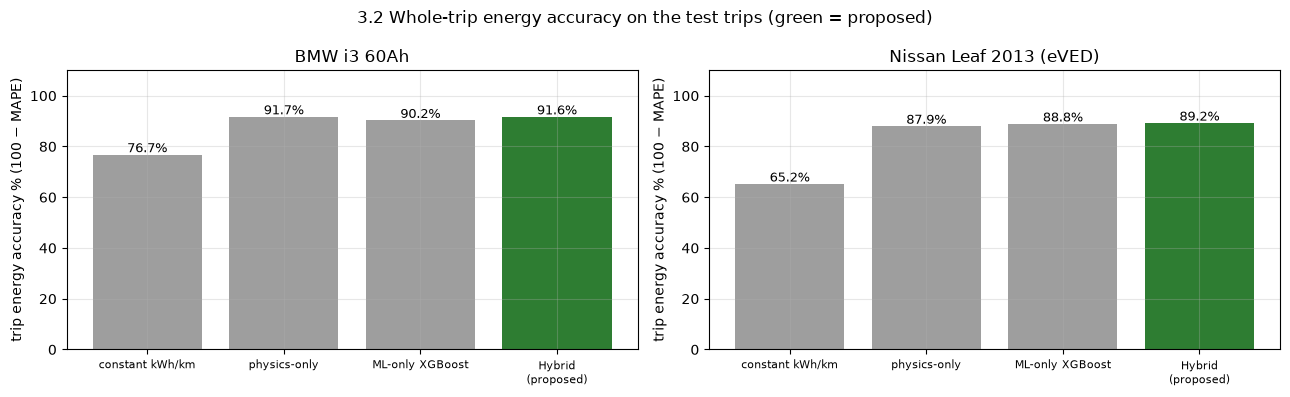

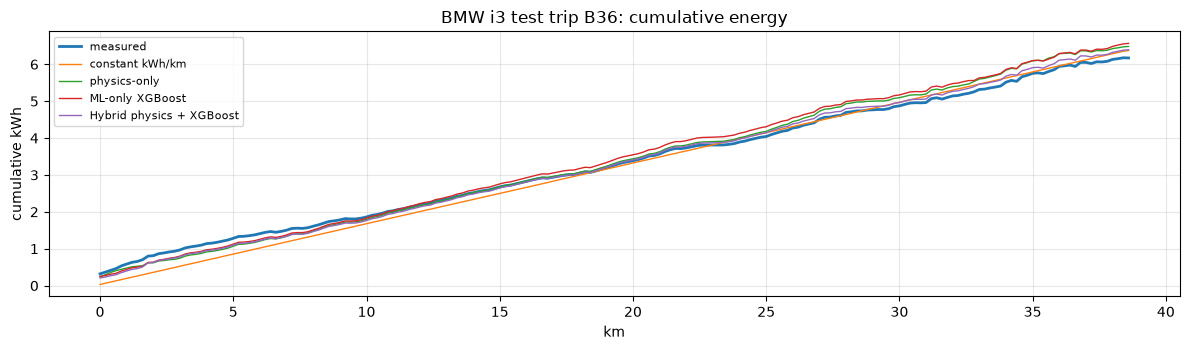

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, d) in zip(axes, DATA.items()):
    a = ACC[ACC.vehicle == d["label"]]
    colors = ["#2e7d32" if "proposed" in m else "#9e9e9e" for m in a.method]
    ax.bar(range(len(a)), a["trip_accuracy_%"], color=colors)
    for i, v in enumerate(a["trip_accuracy_%"]): ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_xticks(range(len(a))); ax.set_xticklabels([m.split(" (")[0].replace("Hybrid physics + XGBoost", "Hybrid\n(proposed)") for m in a.method], fontsize=8)
    ax.set_ylim(0, 110); ax.set_ylabel("trip energy accuracy % (100 − MAPE)"); ax.set_title(d["label"])
fig.suptitle("3.2 Whole-trip energy accuracy on the test trips (green = proposed)")
fig.tight_layout(); fig.savefig(FIG / "3_2_trip_accuracy.png", dpi=120); plt.show()

d = DATA["bmw"]; te = d["seg"][d["seg"].split == "test"]
tid = te.groupby("trip_id").dist_m.sum().idxmax(); t = te[te.trip_id == tid].sort_values("seg")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(t.seg * 0.2, t.energy_kwh.cumsum(), label="measured", lw=2)
for col, lab in METHODS.items(): ax.plot(t.seg * 0.2, t[col].cumsum(), label=lab.split(" (")[0], lw=1)
ax.set_xlabel("km"); ax.set_ylabel("cumulative kWh"); ax.set_title(f"BMW i3 test trip {tid}: cumulative energy"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "3_2_example_trip.png", dpi=120); plt.show()

## 3.3 SoC tracking on a Sri Lankan hill corridor – Colombo → Nuwara Eliya (scenario)

⚠️ **Approximation, not a real route:** OSRM is not set up yet, so the corridor is a polyline through approximate
town locations (Colombo – Kadawatha – Nittambuwa – Kegalle – Mawanella – Kadugannawa – Peradeniya – Gampola –
Ramboda – Nuwara Eliya). Elevation every 200 m from the **Copernicus DEM**, smoothed over 1 km. Straight lines between
towns are shorter than the road (real road ≈ 170 km), and the speed profile is assumed (urban 30, A-road 50,
hill section 35 km/h). Temperature from the Open-Meteo data (Colombo / Kandy / Nuwara Eliya means).
Vehicle = BMW i3 60 Ah (usable 18.8 kWh, Open EV Data), start SoC 100 %, reserve 15 %.

In [8]:
WAY = [("Colombo", 6.9344, 79.8428), ("Kadawatha", 7.0010, 79.9530), ("Nittambuwa", 7.1440, 80.0960),
       ("Kegalle", 7.2513, 80.3464), ("Mawanella", 7.2520, 80.4440), ("Kadugannawa", 7.2540, 80.5240),
       ("Peradeniya", 7.2690, 80.5940), ("Gampola", 7.1640, 80.5770), ("Ramboda", 7.0580, 80.6950),
       ("Nuwara Eliya", 6.9497, 80.7891)]
import pyproj
geod = pyproj.Geod(ellps="WGS84")
pts = []
for (n1, la1, lo1), (n2, la2, lo2) in zip(WAY[:-1], WAY[1:]):
    dist = geod.inv(lo1, la1, lo2, la2)[2]
    k = max(int(dist // SEG_LEN), 1)
    for (lo, la) in [(lo1, la1)] + geod.npts(lo1, la1, lo2, la2, k - 1):
        pts.append((lo, la, n1))
pts.append((WAY[-1][2], WAY[-1][1], WAY[-1][0]))
R = pd.DataFrame(pts, columns=["lon", "lat", "leg"])
idx = pd.read_parquet(PROC / "dem_tiles_index.parquet")
R["elev_raw"] = c3other.sample_elevation(idx, RAW / "elevation_copernicus_dem", R.lon.to_numpy(), R.lat.to_numpy())
R["elev"] = R.elev_raw.rolling(5, center=True, min_periods=1).mean()
step = np.r_[0, [geod.inv(a, b, c, e)[2] for a, b, c, e in zip(R.lon[:-1], R.lat[:-1], R.lon[1:], R.lat[1:])]]
R["km"] = np.cumsum(step) / 1000
R = R.iloc[1:].reset_index(drop=True); R["dist_m"] = step[1:]
R["elev_change_m"] = R.elev.diff().fillna(0); R["grade_pct"] = 100 * R.elev_change_m / R.dist_m
R["speed"] = np.where(R.km < 15, 30, np.where(R.km < 100, 50, 35)).astype(float)
w = pd.read_parquet(PROC / "weather_hourly.parquet").groupby("town").temp_c.mean()
R["amb"] = np.where(R.km < 100, w["Colombo"], np.where(R.km < 125, w["Kandy"], w["NuwaraEliya"]))
print(f"corridor: {R.km.iloc[-1]:.0f} km (straight town-to-town lines) | elevation {R.elev.iloc[0]:.0f} m -> {R.elev.iloc[-1]:.0f} m "
      f"(max {R.elev.max():.0f} m) | total climb {R.elev_change_m.clip(lower=0).sum():.0f} m")

corridor: 139 km (straight town-to-town lines) | elevation 11 m -> 1886 m (max 2011 m) | total climb 3753 m


Colombo -> Nuwara Eliya {'constant kWh/km': '22.9 kWh', 'physics-only': '22.0 kWh', 'hybrid (proposed)': '20.8 kWh'}
Nuwara Eliya -> Colombo {'constant kWh/km': '22.9 kWh', 'physics-only': '7.8 kWh', 'hybrid (proposed)': '9.1 kWh'}


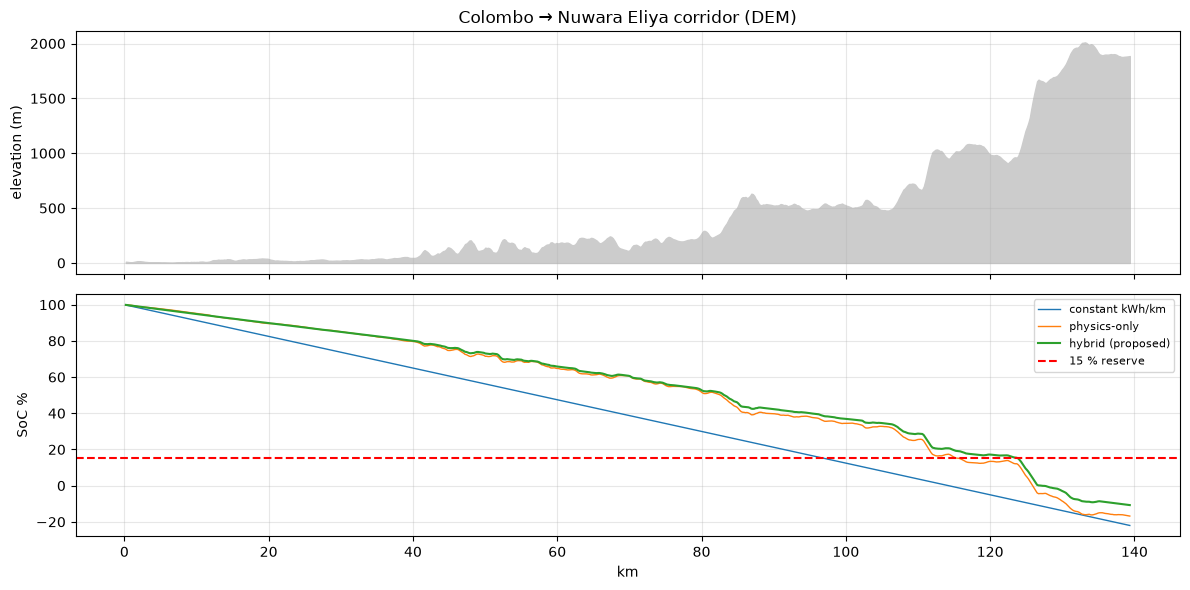

In [9]:
def route_segments(R, reverse=False):
    S = R.iloc[::-1].copy() if reverse else R.copy()
    if reverse:
        S["elev_change_m"] = -S["elev_change_m"]; S["grade_pct"] = -S["grade_pct"]
    v = S.speed / 3.6; dur = S.dist_m / v; th = np.arctan(S.grade_pct.clip(-25, 25) / 100)
    seg = pd.DataFrame({"dist_m": S.dist_m.values, "duration_s": dur.values, "speed_mean_kmh": S.speed.values,
        "speed_std_kmh": 5.0, "speed_max_kmh": S.speed.values + 10, "n_stops": 0.1, "stopped_s": 0.0,
        "acc_pos_mean": 0.15, "acc_neg_mean": -0.15, "elev_change_m": S.elev_change_m.values, "grade_pct": S.grade_pct.values,
        "ambient_c_mean": S.amb.values, "kinetic_term": (G * np.sin(th) * v * dur).values, "v3_term": (0.5 * RHO * v ** 3 * dur).values})
    ts = pd.DataFrame({"X_acc_grade": seg.kinetic_term, "X_roll": G * np.cos(th.values) * v.values * dur.values,
                       "X_aero": seg.v3_term, "amb": seg.ambient_c_mean, "dt_s": seg.duration_s, "seg_idx": np.arange(len(seg))})
    return seg, ts

d = DATA["bmw"]; USABLE, RESERVE = 18.8, 0.15
corridor = {}
for direction, rev in (("Colombo -> Nuwara Eliya", False), ("Nuwara Eliya -> Colombo", True)):
    seg, ts = route_segments(R, rev)
    seg["pred_physics"] = physics_seg(PHYS["bmw"], ts, len(seg))
    e = {"constant kWh/km": d["kwh_km"] * seg.dist_m / 1000, "physics-only": seg.pred_physics,
         "hybrid (proposed)": seg.pred_physics + d["hybrid"].predict(seg[FEATS + ["pred_physics"]])}
    corridor[direction] = {k: v.to_numpy() for k, v in e.items()}
    print(direction, {k: f"{v.sum():.1f} kWh" for k, v in e.items()})
km = R.km.to_numpy()
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].fill_between(km, R.elev, color="0.8"); ax[0].set_ylabel("elevation (m)"); ax[0].set_title("Colombo → Nuwara Eliya corridor (DEM)")
for k, e in corridor["Colombo -> Nuwara Eliya"].items():
    soc = 100 - 100 * np.cumsum(e) / USABLE
    ax[1].plot(km, soc, label=k, lw=1.5 if "hybrid" in k else 1)
ax[1].axhline(100 * RESERVE, color="r", ls="--", label="15 % reserve"); ax[1].set_ylabel("SoC %"); ax[1].set_xlabel("km")
ax[1].legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / "3_3_corridor_soc.png", dpi=120); plt.show()

In [10]:
up = corridor["Colombo -> Nuwara Eliya"]
need_kwh = {k: float(v.sum()) for k, v in up.items()}
km_at_reserve = {k: (float(km[np.argmax(100 - 100 * np.cumsum(v) / USABLE <= 100 * RESERVE)])
                     if (100 - 100 * np.cumsum(v) / USABLE <= 100 * RESERVE).any() else None) for k, v in up.items()}
hill = km >= 110
climb = {k: float(v[hill].sum()) for k, v in up.items()}
down = {k: float(v.sum()) for k, v in corridor["Nuwara Eliya -> Colombo"].items()}
C33 = pd.DataFrame({"trip_kWh_up": need_kwh, "km_when_SoC_hits_15%": km_at_reserve,
                    "hill_section_kWh (km>=110)": climb, "trip_kWh_down": down})
RESULTS["metrics"]["3.3_corridor_scenario"] = C33.round(3).to_dict(orient="index")
display(C33.round(2))
print("Constant kWh/km cannot see the 1,900 m climb: it predicts the same energy up and down.")

,trip_kWh_up,km_when_SoC_hits_15%,hill_section_kWh (km>=110),trip_kWh_down
constant kWh/km,22.94,97.24,4.83,22.94
physics-only,21.96,115.84,7.96,7.78
hybrid (proposed),20.82,124.10,7.43,9.11


Constant kWh/km cannot see the 1,900 m climb: it predicts the same energy up and down.


## 3.4 Charging-stop choice (scenario)

If the car would reach the 15 % reserve, it must stop **before** that point. Candidate chargers = OSM charging
stations within 5 km of the corridor and before the reserve point. Score (rule-based):
`0.4·(position: later is better, uses more of the battery) + 0.3·(charger power) + 0.2·(short detour) + 0.1·(not busy)`.
⚠️ Busyness = 0.5 placeholder (C1 forecast comes after merging). Charger kW missing in OSM → assumed 22 kW AC.
Baseline = **nearest** charger to the reserve point.

In [11]:
ch = json.loads((ROOT / "shared/data/raw/chargers/osm_charging_stations_LK_2026-10-19.json").read_text(encoding="utf-8"))["elements"]
import re
CH = pd.DataFrame([{"name": (e.get("tags", {}).get("name") or e.get("tags", {}).get("operator") or "unnamed")
                            + f" (osm {e['type'][0]}{e['id']})",
                    "lon": e.get("lon") or e["center"]["lon"], "lat": e.get("lat") or e["center"]["lat"]} for e in ch])
def kw_of(t):
    v = [float(x) for k, s in t.items() if k.endswith("output") for x in re.findall(r"(\d+(?:\.\d+)?)\s*kw", s.lower())]
    return max(v) if v else np.nan
CH["kw"] = [kw_of(e.get("tags", {})) for e in ch]
CH["kw_used"] = CH.kw.fillna(22.0)
dmin, imin = [], []
for _, c in CH.iterrows():
    dd = np.array(geod.inv(np.full(len(R), c.lon), np.full(len(R), c.lat), R.lon.to_numpy(), R.lat.to_numpy())[2])
    dmin.append(dd.min()); imin.append(int(dd.argmin()))
CH["dist_to_route_km"] = np.array(dmin) / 1000; CH["route_km"] = km[np.array(imin)]
e = up["hybrid (proposed)"]; soc = 100 - 100 * np.cumsum(e) / USABLE
limit_km = km_at_reserve["hybrid (proposed)"] or km[-1]
cand = CH[(CH.dist_to_route_km <= 5) & (CH.route_km < limit_km)].copy()
if len(cand):
    norm = lambda s: (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0 + 1
    cand["soc_at_arrival_%"] = [float(soc[np.searchsorted(km, k)]) for k in cand.route_km]
    cand["score"] = 0.4 * norm(cand.route_km) + 0.3 * norm(cand.kw_used) + 0.2 * (1 - norm(cand.dist_to_route_km)) + 0.1 * 0.5
    best = cand.sort_values("score", ascending=False).iloc[0]
    nearest = cand.iloc[(cand.route_km - limit_km).abs().argmin()]
    display(cand.sort_values("score", ascending=False)[["name", "route_km", "dist_to_route_km", "kw", "kw_used", "soc_at_arrival_%", "score"]].round(2))
    RESULTS["metrics"]["3.4_stop_choice"] = {
        "reserve_point_km": float(limit_km), "candidates": len(cand),
        "recommended": {"name": best["name"], "route_km": float(best.route_km), "kw": float(best.kw_used), "soc_arrival_%": float(best["soc_at_arrival_%"])},
        "nearest_baseline": {"name": nearest["name"], "route_km": float(nearest.route_km), "kw": float(nearest.kw_used)}}
    print("recommended:", RESULTS["metrics"]["3.4_stop_choice"]["recommended"]); print("nearest baseline:", RESULTS["metrics"]["3.4_stop_choice"]["nearest_baseline"])
else:
    RESULTS["metrics"]["3.4_stop_choice"] = {"reserve_point_km": float(limit_km), "candidates": 0,
                                             "note": "no OSM charger within 5 km of the corridor before the reserve point"}
    print("No OSM charger within 5 km before the reserve point – OSM list is incomplete (needs operator lists).")

,name,route_km,dist_to_route_km,kw,kw_used,soc_at_arrival_%,score
22,unnamed (osm n4451144490),89.13,0.48,NaN,22.0,42.67,0.91
18,unnamed (osm n4451143990),94.20,1.19,NaN,22.0,40.44,0.90
19,unnamed (osm n4451143991),76.64,0.04,NaN,22.0,55.23,0.87
27,unnamed (osm n4451148789),73.39,0.52,NaN,22.0,57.20,0.84
49,unnamed (osm n13031797276),94.20,4.30,NaN,22.0,40.44,0.76
37,unnamed (osm n4459877593),17.25,0.06,NaN,22.0,91.17,0.62
40,unnamed (osm n4459877794),14.43,0.01,NaN,22.0,92.59,0.61
29,Car Charging Station (osm n4451148890),12.43,0.06,NaN,22.0,93.59,0.60
15,unnamed (osm n4451141691),52.03,4.52,NaN,22.0,71.28,0.57
30,unnamed (osm n4451148891),6.61,0.31,NaN,22.0,96.59,0.56


recommended: {'name': 'unnamed (osm n4451144490)', 'route_km': 89.13417210407019, 'kw': 22.0, 'soc_arrival_%': 42.67311505554748}
nearest baseline: {'name': 'unnamed (osm n4451143990)', 'route_km': 94.20229409615102, 'kw': 22.0}


## ✅ C3 accuracy summary (test split)

Main number for the thesis = **whole-trip energy error** (what matters for range / SoC). Segment errors are also shown.

In [12]:
S = ACC[["vehicle", "method", "trip_MAE_kWh", "trip_MAPE_%", "trip_accuracy_%", "segment_MAE_Wh", "segment_WAPE_%",
         "flat_MAE_Wh", "hilly_MAE_Wh (|grade|>=2%)"]].copy()
display(S.style.apply(hl, axis=1).format(precision=2).hide(axis="index"))
for v in ACC.vehicle.unique():
    a = ACC[ACC.vehicle == v].set_index("method")
    hyb = a.loc["Hybrid physics + XGBoost (proposed)"]
    best_base = a.drop("Hybrid physics + XGBoost (proposed)")["trip_MAE_kWh"].idxmin()
    print(f"{v}: hybrid trip MAE {hyb.trip_MAE_kWh:.3f} kWh vs best baseline ({best_base}) "
          f"{a.loc[best_base, 'trip_MAE_kWh']:.3f} kWh -> {'better' if hyb.trip_MAE_kWh < a.loc[best_base, 'trip_MAE_kWh'] else 'NOT better'}")
ACC.to_csv(RES / f"c3_accuracy_{RUN_ID}.csv", index=False)

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
RESULTS["config"].update({"features": FEATS, "physics_bounds": dict(zip(PNAMES, zip(LB, UB))), "usable_kwh_bmw": USABLE,
                          "reserve": RESERVE, "corridor_waypoints": WAY})
(RES / f"c3_training_{RUN_ID}.json").write_text(json.dumps(clean(RESULTS), indent=2))
print("saved results/c3_training_%s.json" % RUN_ID)

vehicle,method,trip_MAE_kWh,trip_MAPE_%,trip_accuracy_%,segment_MAE_Wh,segment_WAPE_%,flat_MAE_Wh,hilly_MAE_Wh (|grade|>=2%)
BMW i3 60Ah,constant kWh/km (baseline),0.48,23.26,76.74,22.52,64.83,22.21,nan
BMW i3 60Ah,physics-only (baseline),0.25,8.33,91.67,5.81,16.74,5.65,nan
BMW i3 60Ah,ML-only XGBoost (baseline),0.23,9.76,90.24,5.46,15.70,5.30,nan
BMW i3 60Ah,Hybrid physics + XGBoost (proposed),0.24,8.37,91.63,5.27,15.17,5.09,nan
Nissan Leaf 2013 (eVED),constant kWh/km (baseline),0.24,34.83,65.17,21.80,71.74,19.86,26.62
Nissan Leaf 2013 (eVED),physics-only (baseline),0.10,12.05,87.95,6.72,22.10,6.09,8.27
Nissan Leaf 2013 (eVED),ML-only XGBoost (baseline),0.09,11.16,88.84,6.71,22.08,6.05,8.34
Nissan Leaf 2013 (eVED),Hybrid physics + XGBoost (proposed),0.09,10.80,89.20,6.48,21.31,5.90,7.92


BMW i3 60Ah: hybrid trip MAE 0.241 kWh vs best baseline (ML-only XGBoost (baseline)) 0.229 kWh -> NOT better
Nissan Leaf 2013 (eVED): hybrid trip MAE 0.092 kWh vs best baseline (ML-only XGBoost (baseline)) 0.093 kWh -> better
saved results/c3_training_20261019T093634Z.json


## Notes for the thesis / next steps
* Training data is **flat** (Munich, Ann Arbor) – the hybrid's hill accuracy can only be proven with **Sri Lankan pilot trips**;
  the corridor in 3.3 shows the *physics* effect of terrain (constant kWh/km cannot).
* Physics parameters are **fitted** (no spec values in the data). For Sri Lankan models (BYD, MG …) use spec-sheet mass / CdA.
* 3.3 / 3.4 use an approximate town-to-town corridor and an assumed speed profile → replace with **OSRM routes** on the
  Sri Lanka OSM graph and typical speeds; charger list needs operator data; busyness comes from C1 after merging.